# Freya (FRB 20230325A): DSA-110 localization uncertainty

Date: 2026-10-29. Author: Claude (Fable 5.1) for Jakob Faber. Host: h23, environment `casa38`. Status: steps 1 and 2 complete. Step 3 is a sum in this notebook only.

## Result

The DSA-110 position of Freya is RA 05h52m45.107s, Dec +74d12m00.67s (88.187946 deg, 74.200187 deg).
The statistical uncertainty is 0.17 arcsec in RA and 0.11 arcsec in Dec.

The systematic uncertainty is 0.37 arcsec in RA and 0.43 arcsec in Dec.
The sum in quadrature is 0.41 arcsec in RA and 0.44 arcsec in Dec.

The RA systematic value is a floor from the fit prior, not a measurement. See the limits section.

## Problem

The manuscript gives no DSA-110 localization uncertainty for Freya or for the other 11 bursts.
The T3 pipeline on h23 has placeholder functions for image localization and astrometry.
The T3 output `/dataz/dsa110/candidates/230325aaag/Level3/230325aaag.json` has null error fields.
The images from 2023-04-21 are on h23, but no file records the fitted position or the error.
This notebook records the analysis that recovers the uncertainty from those images.

## Inputs

All inputs come from `/media/ubuntu/data/localization_processing/230325aaag/` on h23.
A copy is in `/media/ubuntu/ssd/jfaber/freya_localization/230325aaag/`. The source directory is not changed.

- `img2/imgx.image`: CASA closeup image, 1000 x 1000 pixels, 0.3 arcsec cells, Briggs robust 0.5, uv range more than 0.2 klambda.
- `images/frb-image.fits`: wide field image, 10000 x 10000 pixels, 2 arcsec cells.
- `icrs_image/<name>-dirty.fits`: dirty images of eight calibrators from the RFC (Radio Fundamental Catalog).
- `rfc_idict.npz`: RFC names, positions, and fluxes of ten calibrators.

The recipe is the notebook `/home/ubuntu/vikram/notebooks/localize.ipynb`. A copy is in `/media/ubuntu/ssd/jfaber/freya_localization/recipe/`.
The functions below are copies of the functions in that notebook.

In [1]:
import numpy as np, os, glob
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
import astropy.units as u
from astropy.coordinates import SkyCoord
from scipy.interpolate import RectBivariateSpline as rbs
from scipy.optimize import minimize
from scipy.ndimage import shift
import warnings; warnings.filterwarnings("ignore")
from casatools import image as imtool
from casatasks import exportfits

D = "/media/ubuntu/ssd/jfaber/freya_localization/230325aaag"
scl = 0.3   # arcsec per pixel in the closeup and calibrator images

def fit_src(image, ira, idec, nside=100):
    nont = int(nside/2)
    mydata = image[idec-nont:idec+nont, ira-nont:ira+nont]
    if idec-nont < 0 or idec+nont >= image.shape[0] or ira-nont < 0 or ira+nont >= image.shape[1]: return None
    if not mydata[nont, nont] > 0.: return None
    x = np.arange(nside)-(nside/2.+0.5); y = np.arange(nside)-(nside/2.+0.5)
    p = rbs(x, y, mydata)
    manyx = np.linspace(x.min(), x.max(), nside*20); manyy = np.linspace(y.min(), y.max(), nside*20)
    interps = p(manyx, manyy); wrs = np.where(interps == interps.max())
    return interps.max(), manyx[wrs[0]][0], manyy[wrs[1]][0]   # amp, dDec pix, dRA pix (image x)

def line_model(pars, x): return pars[0]*np.array(x) + pars[1]

class StraightLineIntrinsicScatterModel:
    def __init__(s, x, y, yerr): s.x = np.asarray(x); s.y = np.asarray(y); s.yerr = np.asarray(yerr)
    def ln_likelihood(s, pars):
        a, b, lnV = pars
        if a < -2 or a > 2 or b < -10 or b > 10 or lnV < -2 or lnV > 2: return -np.inf
        V = np.exp(lnV); dy = s.y - line_model([a, b], s.x); var = s.yerr**2 + V
        return -0.5*np.sum(dy**2/var + np.log(2*np.pi*var))

## Step 0: start position

The T3 output gives the position 89.2751 deg, 71.6491 deg. This is the T2 beam position.
The peak of the wide field image is 2.6 deg from the T2 position.
The closeup image has its phase center at that peak. The configuration `analysis/config/bursts.yaml` gives 88.188 deg, 74.200472 deg.

Thus the analysis uses the closeup phase center as the start position. The T2 position is not a correct start position.

wide field peak 0.1910 Jy/beam at 05h52m44.99377108s +74d12m02.70585627s [88.18747405 74.20075163]
closeup phase center: 05h52m45s +74d12m02.7s
T2 position (Level3 json): 89.2751 71.6491, separation 2.57 deg


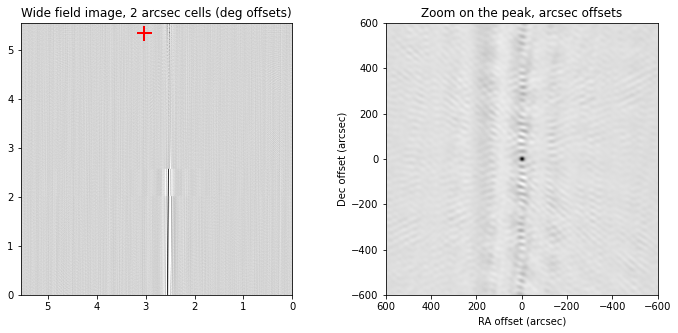

In [2]:
d = fits.open(D+"/images/frb-image.fits"); im = d[0].data[0,0]; w = WCS(d[0].header)
ipk = np.unravel_index(np.nanargmax(im), im.shape)
sky = w.wcs_pix2world([[ipk[1], ipk[0], 1.405e9, 1]], 0)[0]
print("wide field peak %.4f Jy/beam at" % im.max(), SkyCoord(sky[0], sky[1], unit="deg").to_string("hmsdms"), sky[:2])
frbpos = SkyCoord("05h52m45s", "+74d12m02.7s", unit=("hourangle", "deg"))   # closeup phase center
print("closeup phase center:", frbpos.to_string("hmsdms"))
print("T2 position (Level3 json): 89.2751 71.6491, separation %.2f deg" % frbpos.separation(SkyCoord(89.2751, 71.6491, unit="deg")).deg)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(im, origin="lower", vmin=-0.01, vmax=0.05, cmap="gray_r", extent=[10000*2/3600, -0, 0, 10000*2/3600])
ax[0].plot(ipk[1]*2/3600, ipk[0]*2/3600, "r+", ms=15, mew=2); ax[0].set_title("Wide field image, 2 arcsec cells (deg offsets)")
s = 300
ax[1].imshow(im[ipk[0]-s:ipk[0]+s, ipk[1]-s:ipk[1]+s], origin="lower", cmap="gray_r", extent=[s*2, -s*2, -s*2, s*2])
ax[1].set_title("Zoom on the peak, arcsec offsets"); ax[1].set_xlabel("RA offset (arcsec)"); ax[1].set_ylabel("Dec offset (arcsec)")
plt.show()

## Step 1: statistical uncertainty

The CASA image tool reads the restoring beam and the pixels of the closeup image.
The off-source region is the image without a 200 x 200 pixel box around the peak.
The SNR uses the scaled median absolute deviation of that region.
The statistical uncertainty on each axis is the beam FWHM projected on that axis, divided by two times the SNR.

In [3]:
ia = imtool(); ia.open(D+"/img2/imgx.image")
rb = ia.restoringbeam(); dat = ia.getchunk().squeeze(); ia.close()
bmaj = rb["major"]["value"]; bmin = rb["minor"]["value"]; bpa = rb["positionangle"]["value"]
peak = np.nanmax(dat); ipk = np.unravel_index(np.nanargmax(dat), dat.shape)
mask = np.ones(dat.shape, bool); mask[ipk[0]-100:ipk[0]+100, ipk[1]-100:ipk[1]+100] = False
rms_std = np.nanstd(dat[mask]); rms_mad = 1.4826*np.nanmedian(np.abs(dat[mask]-np.nanmedian(dat[mask])))
snr = peak/rms_mad
th = np.deg2rad(bpa)
fw_dec = np.sqrt((bmaj*np.cos(th))**2 + (bmin*np.sin(th))**2)
fw_ra  = np.sqrt((bmaj*np.sin(th))**2 + (bmin*np.cos(th))**2)
sig_stat_ra = fw_ra/(2*snr); sig_stat_dec = fw_dec/(2*snr)
print("beam %.2f x %.2f arcsec, PA %.1f deg" % (bmaj, bmin, bpa))
print("peak %.4f Jy/beam; rms std %.5f, rms MAD %.5f Jy/beam; SNR(MAD) %.1f; SNR(std) %.1f" % (peak, rms_std, rms_mad, snr, peak/rms_std))
print("beam FWHM projected: RA %.2f, Dec %.2f arcsec" % (fw_ra, fw_dec))
print("sigma_stat: RA %.3f, Dec %.3f arcsec" % (sig_stat_ra, sig_stat_dec))

beam 26.74 x 16.06 arcsec, PA 79.8 deg
peak 0.1956 Jy/beam; rms std 0.00304, rms MAD 0.00253 Jy/beam; SNR(MAD) 77.5; SNR(std) 64.3
beam FWHM projected: RA 26.47, Dec 16.50 arcsec
sigma_stat: RA 0.171, Dec 0.106 arcsec


In [4]:
fcl = D+"/img2/imgx_closeup.fits"; fpsf = D+"/img2/imgx_psf.fits"
if not os.path.exists(fcl): exportfits(imagename=D+"/img2/imgx.image", fitsimage=fcl)
if not os.path.exists(fpsf): exportfits(imagename=D+"/img2/imgx.psf", fitsimage=fpsf)
d3 = fits.open(fcl); image3 = d3[0].data[0,0]; w3 = WCS(d3[0].header)
dpsf = fits.open(fpsf)[0].data[0,0]
pc = w3.wcs_world2pix(np.array([[frbpos.ra.deg, frbpos.dec.deg, 1.405e9, 1.]]), 0)
rapix = int(np.floor(pc[0,0])); depix = int(np.floor(pc[0,1]))
famp, myfdec, myfra = fit_src(image3, rapix, depix, nside=400)
fra = -scl*myfra; fdec = scl*myfdec
fit_ra = frbpos.ra + fra*u.arcsec; fit_dec = frbpos.dec + fdec*u.arcsec
fitpos = SkyCoord(fit_ra, fit_dec)
print("fit_src amplitude %.4f Jy/beam; offset from phase center RA %.2f, Dec %.2f arcsec" % (famp, fra, fdec))
print("fitted position:", fitpos.to_string("hmsdms"))

fit_src amplitude 0.1956 Jy/beam; offset from phase center RA 0.64, Dec -1.13 arcsec
fitted position: 05h52m45.04244656s +74d12m01.56947743s


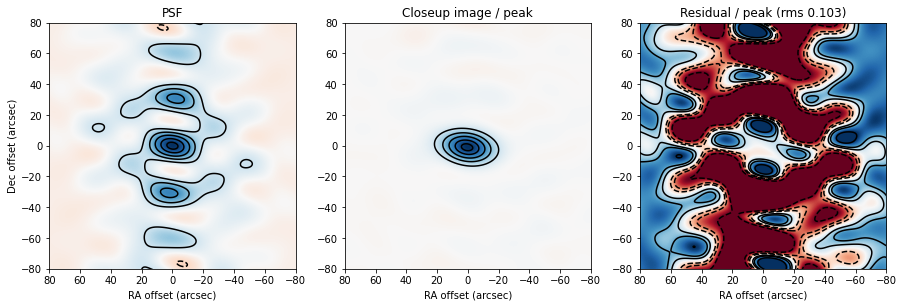

In [5]:
# Figure: PSF, image, residual (notebook cell 21 layout)
shift_dpsf = shift(dpsf, [myfdec, myfra]); dresid = image3 - shift_dpsf*famp
n = image3.shape[0]//2
x = np.arange(n*scl, -n*scl, -scl); y = np.arange(-n*scl, n*scl, scl); xx, yy = np.meshgrid(x, y)
extent = [n*scl, -n*scl, -n*scl, n*scl]; levs = [-0.4,-0.2,0.2,0.4,0.6,0.8,0.95]; levs2 = [-0.1,-0.05,-0.025,0.025,0.05,0.1]; lt = 80.
fig = plt.figure(figsize=(15, 5))
for k, (arr, ttl, lv, vm) in enumerate([(dpsf, "PSF", levs, 1.), (image3/famp, "Closeup image / peak", levs, 1.), (dresid/famp, "Residual / peak (rms %.3f)" % np.std(dresid/famp), levs2, 0.1)]):
    ax = fig.add_subplot(1, 3, k+1); ax.set_aspect("equal")
    ax.imshow(arr, vmin=-vm, vmax=vm, extent=extent, cmap="RdBu", origin="lower"); ax.contour(xx, yy, arr, levels=lv, colors="k")
    ax.set_xlim(lt, -lt); ax.set_ylim(-lt, lt); ax.set_title(ttl); ax.set_xlabel("RA offset (arcsec)")
fig.axes[0].set_ylabel("Dec offset (arcsec)"); plt.show()

## Step 2: systematic uncertainty

The function `fit_src` finds the peak in each calibrator dirty image, with a 300 pixel box around the RFC position.
The offset is the fitted peak minus the RFC position.
The recipe removes a source more than 10 pixels from its RFC position.
Each source that stays has an error of 0.45 x 25 / (1000 x flux) arcsec, from the recipe.
A straight line with intrinsic scatter is then fitted to the offsets as a function of RA, for each axis.
The optimizer is scipy BFGS from the start point (0.01, 0, 0), with the flat priors of the recipe.

In [6]:
idict = np.load(D+"/rfc_idict.npz", allow_pickle=True)["idict"].item()
rows = []
for i, n in enumerate(idict["jname"]):
    f = D+"/icrs_image/"+n+"-dirty.fits"
    if not os.path.exists(f): rows.append((n, idict["flux"][i], np.nan, np.nan, np.nan, "no image")); continue
    d = fits.open(f); image = d[0].data[0,0]; w = WCS(d[0].header)
    pcc = w.wcs_world2pix(np.array([[idict["position"][i].ra.deg, idict["position"][i].dec.deg, 1.405e9, 1.]]), 0)
    pp = fit_src(image, int(np.floor(pcc[0,0])), int(np.floor(pcc[0,1])), nside=300)
    if pp is None: rows.append((n, idict["flux"][i], np.nan, np.nan, np.nan, "fit failed")); continue
    a, fx_, fy_ = pp; r = np.hypot(fx_, fy_)
    rows.append((n, idict["flux"][i], a, -scl*fy_, scl*fx_, "used" if r <= 10 else "rejected, %.1f pixels" % r))
print("%-11s %7s %9s %8s %8s  %s" % ("name", "RFCflux", "amp", "dRA", "dDec", "status"))
for r in rows: print("%-11s %7.3f %9.4f %8.2f %8.2f  %s" % r)
used = [r for r in rows if r[5] == "used" and r[2] > 0.001]
fx = np.array([r[3] for r in used]); fy = np.array([r[4] for r in used])
mmyx = np.array([idict["position"][idict["jname"].index(r[0])].ra.deg for r in used]); mmyflux = np.array([r[1] for r in used])
mmyerr = 0.45*25./(1000.*mmyflux)
rx = minimize(lambda p: -StraightLineIntrinsicScatterModel(mmyx, fx, mmyerr).ln_likelihood(p), x0=[0.01,0,0], method="BFGS")
ry = minimize(lambda p: -StraightLineIntrinsicScatterModel(mmyx, fy, mmyerr).ln_likelihood(p), x0=[0.01,0,0], method="BFGS")
sig_sys_ra = np.sqrt(np.exp(rx.x[2])); sig_sys_dec = np.sqrt(np.exp(ry.x[2]))
frbx = fit_ra.deg
off_ra = line_model(rx.x[:2], frbx); off_dec = line_model(ry.x[:2], frbx)
print("\nRA fit  (slope, intercept, lnV):", np.round(rx.x, 4), " sigma %.2f arcsec; raw std %.2f" % (sig_sys_ra, fx.std()))
print("Dec fit (slope, intercept, lnV):", np.round(ry.x, 4), " sigma %.2f arcsec; raw std %.2f" % (sig_sys_dec, fy.std()))
print("offset at FRB RA: RA %.2f, Dec %.2f arcsec" % (off_ra, off_dec))

name        RFCflux       amp      dRA     dDec  status
J0519+7133    0.241    0.2123    -0.50     1.19  used
J0501+7128    0.187    0.1337    -0.53     1.17  used
J0544+7132    0.108    0.0508    -1.25     1.01  used
J0636+7138    0.092    0.0840    -0.89     0.92  used
J0643+7236    0.086    0.0428    -1.41     0.17  used
J0606+7116    0.084    0.1555     1.62     3.33  rejected, 12.3 pixels
J0622+7242    0.079    0.0148    -1.80     1.07  used
J0453+7148    0.069       nan      nan      nan  no image
J0719+7245    0.063       nan      nan      nan  no image
J0611+7218    0.053    0.0950   -44.55    -9.91  rejected, 152.1 pixels

RA fit  (slope, intercept, lnV): [-0.0255  1.2829 -1.9736]  sigma 0.37 arcsec; raw std 0.47
Dec fit (slope, intercept, lnV): [ 1.6000e-03  7.5300e-01 -1.7051e+00]  sigma 0.43 arcsec; raw std 0.35
offset at FRB RA: RA -0.97, Dec 0.90 arcsec


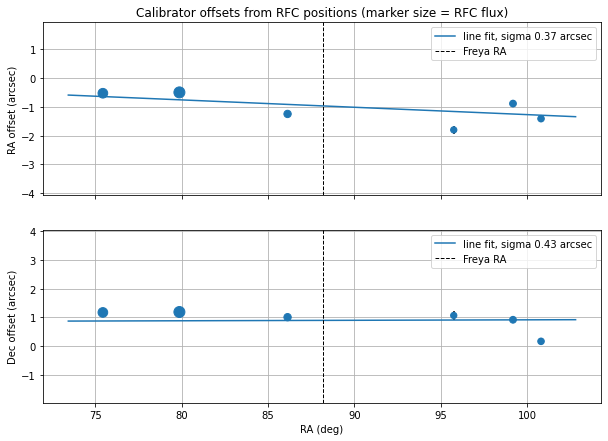

In [7]:
# Figure: calibrator offsets as a function of RA (notebook cell 16 layout)
ylt = 3.
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for a, yy_, res, lab in [(ax[0], fx, rx, "RA"), (ax[1], fy, ry, "Dec")]:
    a.scatter(mmyx, yy_, s=mmyflux/0.002, zorder=3); a.errorbar(mmyx, yy_, fmt=".", yerr=mmyerr, color="k")
    xs = np.linspace(mmyx.min()-2, mmyx.max()+2, 50)
    a.plot(xs, line_model(res.x[:2], xs), "-", label="line fit, sigma %.2f arcsec" % np.sqrt(np.exp(res.x[2])))
    a.axvline(frbx, color="k", ls="--", lw=1, label="Freya RA"); a.set_ylim(np.median(yy_)-ylt, np.median(yy_)+ylt)
    a.set_ylabel("%s offset (arcsec)" % lab); a.grid(); a.legend()
ax[1].set_xlabel("RA (deg)"); ax[0].set_title("Calibrator offsets from RFC positions (marker size = RFC flux)"); plt.show()

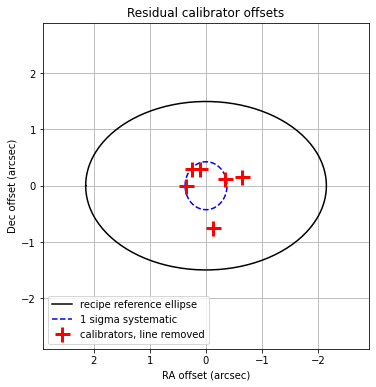

In [8]:
# Figure: offsets after the line correction, with the beam ellipse (notebook cell 22, panel 4)
vlbi_raoff = fx - line_model(rx.x[:2], mmyx); vlbi_decoff = fy - line_model(ry.x[:2], mmyx)
t = np.linspace(0, 2*np.pi, 200)
fig, ax = plt.subplots(figsize=(6, 6)); ax.set_aspect("equal")
ax.plot(2.14*np.cos(t), 0.7*2.14*np.sin(t), "k-", label="recipe reference ellipse")
ax.plot(sig_sys_ra*np.cos(t), sig_sys_dec*np.sin(t), "b--", label="1 sigma systematic")
ax.plot(vlbi_raoff, vlbi_decoff, "r+", ms=15, mew=3, label="calibrators, line removed")
ax.set_xlim(2.9, -2.9); ax.set_ylim(-2.9, 2.9); ax.grid(); ax.legend(loc="lower left")
ax.set_xlabel("RA offset (arcsec)"); ax.set_ylabel("Dec offset (arcsec)"); ax.set_title("Residual calibrator offsets"); plt.show()

## Step 3: corrected position and combined uncertainty

The analysis subtracts the line offset at the RA of Freya from the fitted position.
The recipe adds the systematic sigma and the statistical uncertainty in quadrature.
This step is a sum in this notebook only. The file `analysis/config/bursts.yaml` does not contain the values.

In [9]:
corr = SkyCoord(fit_ra - off_ra*u.arcsec, fit_dec - off_dec*u.arcsec)
tot_ra = np.hypot(sig_stat_ra, sig_sys_ra); tot_dec = np.hypot(sig_stat_dec, sig_sys_dec)
print("corrected position:", corr.to_string("hmsdms"), " (%.6f, %.6f) deg" % (corr.ra.deg, corr.dec.deg))
print("sigma_stat  RA %.2f  Dec %.2f arcsec" % (sig_stat_ra, sig_stat_dec))
print("sigma_sys   RA %.2f  Dec %.2f arcsec" % (sig_sys_ra, sig_sys_dec))
print("combined    RA %.2f  Dec %.2f arcsec" % (tot_ra, tot_dec))
print("combined with raw RA std: RA %.2f arcsec" % np.hypot(sig_stat_ra, fx.std()))

corrected position: 05h52m45.10710118s +74d12m00.67229817s  (88.187946, 74.200187) deg
sigma_stat  RA 0.17  Dec 0.11 arcsec
sigma_sys   RA 0.37  Dec 0.43 arcsec
combined    RA 0.41  Dec 0.44 arcsec
combined with raw RA std: RA 0.50 arcsec


## Limits

- The RA fit stopped at the prior bound. The prior keeps ln V above -2, which is a sigma of 0.37 arcsec. The fit gives ln V of -1.97. Six points cannot constrain the scatter below this floor. The raw standard deviation of 0.47 arcsec is the conservative RA value.
- Two calibrators have no images. The recipe rejects two more. No one examined them again. A new image of J0606+7116 can add a seventh point.
- The recipe gives the error as the sum in quadrature of the sigma and the statistical term. It does not give the convention for the beam projection. This notebook uses the beam projected on each axis.
- The statistical term uses the scaled median absolute deviation. The standard deviation gives an SNR of 64 and a statistical term of 0.21 arcsec in RA and 0.13 arcsec in Dec. The combined values change by less than 0.02 arcsec.
- The fitted position in step 1 is 1.3 arcsec from the manuscript value. The manuscript value is the phase center, not a fit.
- No second person or agent examined this analysis.